In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from dataclasses import dataclass

In [ ]:
@dataclass
class batched_npz:
    names: list[str]
    metadata: dict
    df: pd.DataFrame

In [16]:
def load_npz(path: str) -> batched_npz:
    d = np.load(path)
    
    names = list(d["parameter_names"])
    metadata = json.loads(str(d["metadata"]))
    df = pd.DataFrame({
        "batch" : d["batch"],
        "T" : d["tally_mean"],
        "T_std" : d["tally_std_dev"]
    })
    for key in ("gradient", "dJ", "datt"):
        for i, name in enumerate(names):
            df[f"{key}_{name}"] = d[key][:, i]
        
    return batched_npz(names, metadata, df)
    

In [17]:
data_y0 = load_npz("data/batch-convergence/r2_x5_y0.npz")
data_y2 = load_npz("data/batch-convergence/r2_x5_y2.npz")

In [18]:
data_y0.df.head()

,batch,T,T_std,gradient_r,gradient_x0,gradient_y0,dJ_r,dJ_x0,dJ_y0,datt_r,datt_x0,datt_y0
0,1,0.077290,inf,-0.015605,-0.002022,0.000396,0.022369,-0.004539,0.000293,-0.037974,0.002518,0.000103
1,2,0.076803,0.000487,-0.014918,-0.002289,0.001209,0.022809,-0.004778,0.001303,-0.037727,0.002488,-0.000094
2,3,0.076778,0.000282,-0.013645,-0.002836,0.000901,0.024091,-0.005333,0.000855,-0.037737,0.002497,0.000046
3,4,0.076779,0.000200,-0.013784,-0.002715,0.001129,0.023988,-0.005233,0.001169,-0.037772,0.002518,-0.000040
4,5,0.077216,0.000463,-0.014334,-0.002507,0.001017,0.023631,-0.005034,0.001068,-0.037964,0.002527,-0.000051


In [19]:
data_y2.df.head()

,batch,T,T_std,gradient_r,gradient_x0,gradient_y0,dJ_r,dJ_x0,dJ_y0,datt_r,datt_x0,datt_y0
0,1,0.123468,inf,-0.040472,-0.001849,0.039385,0.015009,-0.000902,-0.006553,-0.055481,-0.000947,0.045938
1,2,0.124096,0.000628,-0.038909,-0.002244,0.038906,0.017725,-0.001330,-0.008004,-0.056635,-0.000914,0.046910
2,3,0.123237,0.000932,-0.037629,-0.002215,0.037602,0.018194,-0.001323,-0.008493,-0.055823,-0.000892,0.046096
3,4,0.123295,0.000662,-0.037649,-0.002176,0.037469,0.018639,-0.001280,-0.009095,-0.056288,-0.000896,0.046564
4,5,0.123419,0.000527,-0.038271,-0.002178,0.038026,0.018102,-0.001282,-0.008636,-0.056373,-0.000895,0.046662


<Axes: >

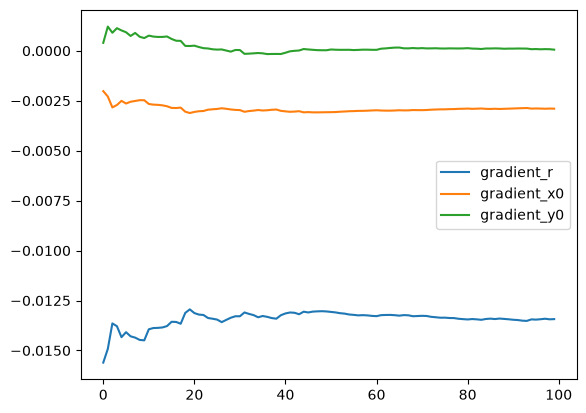

In [23]:
data_y0.df[["gradient_r", "gradient_x0", "gradient_y0"]].plot()

<Axes: >

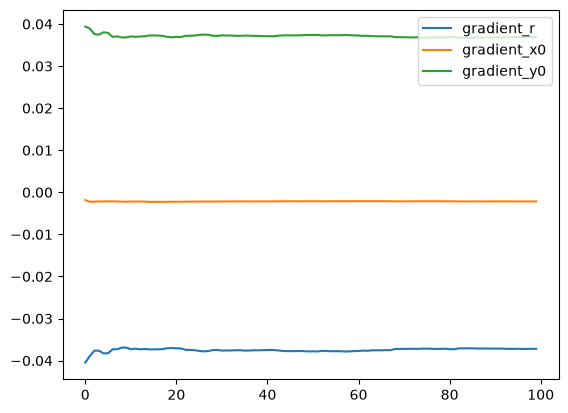

In [24]:
data_y2.df[["gradient_r", "gradient_x0", "gradient_y0"]].plot()

<Axes: >

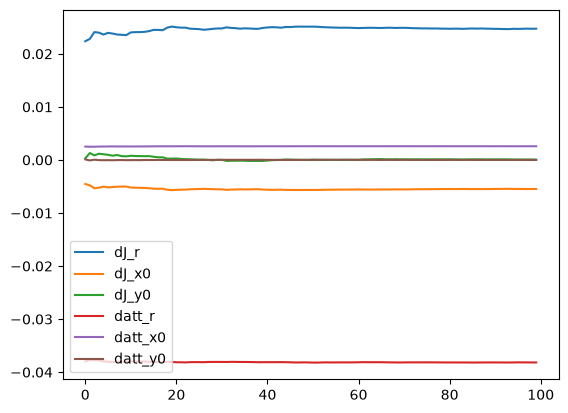

In [27]:
data_y0.df[[
    "dJ_r",
    "dJ_x0",
    "dJ_y0",
    "datt_r",
    "datt_x0",
    "datt_y0"
]].plot()

<Axes: >

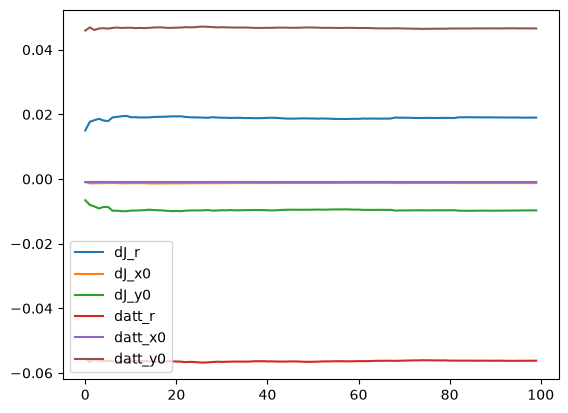

In [28]:
data_y2.df[[
    "dJ_r",
    "dJ_x0",
    "dJ_y0",
    "datt_r",
    "datt_x0",
    "datt_y0"
]].plot()

In [37]:
df_optim = pd.read_csv("data/optimization-budget/results.csv")

In [38]:
df_optim.head()

,batches,particles,seed,T_ref,T_ref_std_dev,r,x0,y0,grad_r,grad_x0,grad_y0,evaluations,iterations,neutrons,optimization_seconds,success,message,error
0,10,10000,1,0.047160,0.000088,7.078077,9.556413,-0.839605,0.000516,-0.004534,-0.000327,50,8,5000000,17.840058,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
1,10,10000,2,0.050383,0.000090,6.644758,8.115002,-0.173757,0.001463,-0.006120,-0.000112,54,8,5400000,19.461795,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
2,10,10000,3,0.046318,0.000089,6.898467,10.000000,-0.968713,-0.000131,-0.003955,-0.000712,49,9,4900000,17.375444,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
3,10,100000,1,0.045983,0.000090,6.612690,10.000000,0.032578,-0.000458,-0.003721,0.000112,35,10,35000000,23.144921,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
4,10,100000,2,0.046140,0.000091,6.787952,10.000000,-0.591761,-0.000201,-0.003878,-0.000312,36,9,36000000,24.027539,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN


In [39]:
df_optim.head(50)

,batches,particles,seed,T_ref,T_ref_std_dev,r,x0,y0,grad_r,grad_x0,grad_y0,evaluations,iterations,neutrons,optimization_seconds,success,message,error
0,10,10000,1,0.047160,0.000088,7.078077,9.556413,-0.839605,0.000516,-0.004534,-0.000327,50,8,5000000,17.840058,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
1,10,10000,2,0.050383,0.000090,6.644758,8.115002,-0.173757,0.001463,-0.006120,-0.000112,54,8,5400000,19.461795,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
2,10,10000,3,0.046318,0.000089,6.898467,10.000000,-0.968713,-0.000131,-0.003955,-0.000712,49,9,4900000,17.375444,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
3,10,100000,1,0.045983,0.000090,6.612690,10.000000,0.032578,-0.000458,-0.003721,0.000112,35,10,35000000,23.144921,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
4,10,100000,2,0.046140,0.000091,6.787952,10.000000,-0.591761,-0.000201,-0.003878,-0.000312,36,9,36000000,24.027539,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
5,10,100000,3,0.046128,0.000094,6.633145,10.000000,-0.691442,-0.000615,-0.003632,-0.000418,32,9,32000000,21.253467,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
6,50,10000,1,0.048144,0.000089,8.073804,10.000000,-1.486657,0.002636,-0.006014,-0.000237,45,8,22500000,23.748173,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
7,50,10000,2,0.046890,0.000094,7.534258,10.000000,-0.057007,0.001237,-0.004822,-0.000094,35,12,17500000,19.916369,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
8,50,10000,3,0.046276,0.000075,7.153118,10.000000,-0.023510,0.000525,-0.004305,0.000002,29,8,14500000,15.366519,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
9,50,100000,1,0.046100,0.000086,6.701198,10.000000,-0.430699,-0.000456,-0.003697,-0.000308,35,9,175000000,75.715076,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,NaN
